# 01: Data: selecting the VidChapters-7M subset

**Goal:** build the training/validation/test set for the chapter models:
- English long videos (15–120 min), stratified by duration
- **every usable Spanish video**
- the transcript (ASR) of each one

Design: [`docs/decisions/0009`](../../docs/decisions/0009-chapter-generator-local-models.md) §1.
Background figures: [`docs/research/m5-chapter-model.md`](../../docs/research/m5-chapter-model.md) §1.

**Sources** (Chapter-Llama mirror, HF `lucas-ventura/chapter-llama`, MIT), in `$YTS_EXPERIMENT_DATA/m5-chapters/raw/`:
- `chapters.json` (2 GB)
- `asrs.json` (22 GB)
- the official split lists `split_{train,val,test}.json`

Neither big file fits in RAM, so both are **streamed** with `ijson`.

**Steps:**
1. **Candidates** from `chapters.json`: duration, number of chapters, chapters of at least 10 s, language detected on the titles.
2. **Selection:** stratified English sample and all Spanish. Spanish gets its own split *by channel* (`es_val` / `es_test`).
3. **ASR extraction** from `asrs.json`: keep only the selected videos, check the transcript is usable, and **re-confirm the language on the transcript text**.
4. **Final statistics** and save to `runs/`.

In [1]:
import json, time, collections
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from dotenv import load_dotenv
load_dotenv('../.env')
from lib import data as d

ROOT = d.data_root(); RAW = ROOT / 'raw'; INTERIM = ROOT / 'interim'; INTERIM.mkdir(parents=True, exist_ok=True)
RUN = Path('runs/2026-09-27-data'); RUN.mkdir(parents=True, exist_ok=True)
CRITERIA = d.Criteria(min_minutes=15, max_minutes=120, min_chapters=3, min_chapter_s=10)
# English videos per (split, duration bucket). Spanish: all of them.
EN_PER_BUCKET = {'train': 3000, 'val': 300, 'test': 500}
lid = d.LanguageId(ROOT.parent / 'models' / 'lid.176.ftz')
print(ROOT, CRITERIA, EN_PER_BUCKET, sep='\n')

/mnt/d/yts-experiments/m5-chapters
Criteria(min_minutes=15, max_minutes=120, min_chapters=3, min_chapter_s=10)
{'train': 3000, 'val': 300, 'test': 500}


## 1. Candidates from `chapters.json`

In [2]:
official = d.load_official_splits(RAW)
t0 = time.time(); total = 0; rows = []
for vid, r in d.iter_chapters(RAW / 'chapters.json'):
    total += 1
    ch = d.parse_chapters(r)
    if not d.is_candidate(r, ch, CRITERIA):
        continue
    lang, score = lid(d.titles_text(r))
    rows.append(dict(vid=vid, duration=r['duration'], bucket=d.duration_bucket(r['duration']),
                     n_chapters=len(ch), channel=r.get('channel_id'), title_lang=lang,
                     title_lang_score=round(score, 3), official=official.get(vid)))
cand = pd.DataFrame(rows)
cand.to_csv(INTERIM / 'candidates.csv', index=False)
print(f'{total:,} videos read in {time.time()-t0:.0f}s -> {len(cand):,} candidates')

816,130 videos read in 44s -> 291,704 candidates


In [3]:
cand['lang'] = np.where(cand.title_lang.isin(['en', 'es']), cand.title_lang, 'other')
pd.crosstab([cand.lang], cand.bucket, margins=True)

bucket,15-30,30-60,60-120,All
lang,,,,
en,153853,81687,49656,285196
es,880,425,186,1491
other,2633,1651,733,5017
All,157366,83763,50575,291704


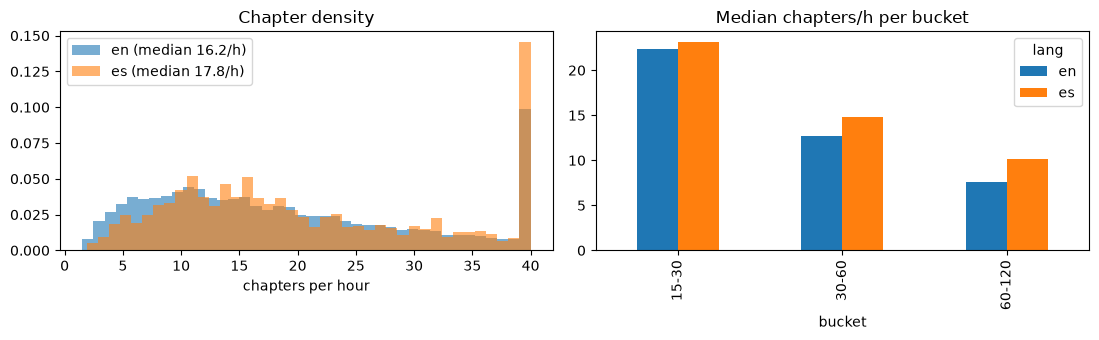

In [4]:
# Chapters per hour: the owner wants "few, broad" chapters (~5–8/h); how do real creators chapter?
cand['chapters_per_hour'] = cand.n_chapters / (cand.duration / 3600)
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for lang in ['en', 'es']:
    s = cand[cand.lang == lang].chapters_per_hour.clip(upper=40)
    ax[0].hist(s, bins=40, alpha=.6, density=True, label=f'{lang} (median {s.median():.1f}/h)')
ax[0].set_xlabel('chapters per hour'); ax[0].legend(); ax[0].set_title('Chapter density')
cand[cand.lang.isin(['en', 'es'])].groupby(['lang', 'bucket']).chapters_per_hour.median().unstack(0).plot.bar(ax=ax[1], title='Median chapters/h per bucket')
plt.tight_layout(); plt.savefig(RUN / 'chapter_density.png', dpi=110); plt.show()

### 1b. Language **of the transcript** (not the titles)

First run (2026-09-27): selecting Spanish by *title* language gave 1 443 "Spanish" videos, but **1 328 of them had an English transcript**. Language ID on short titles is unreliable, and many Spanish-speech videos have English titles. So language is decided on the ASR text, for every candidate. It is one streaming pass over `asrs.json` (~4 min), cached in `candidates_asr_lang.csv`.

In [5]:
cache = INTERIM / 'candidates_asr_lang.csv'
if cache.exists():
    asr_lang = pd.read_csv(cache)[['vid', 'asr_lang', 'asr_lang_score', 'usable']]
else:
    meta = cand.set_index('vid')['duration'].to_dict(); rows = []
    for vid, asr in d.iter_asr(RAW / 'asrs.json', set(meta)):
        lang, score = lid(d.asr_text(asr))
        rows.append((vid, lang, round(score, 3), d.asr_is_usable(asr, meta[vid])))
    asr_lang = pd.DataFrame(rows, columns=['vid', 'asr_lang', 'asr_lang_score', 'usable'])
    asr_lang.merge(cand, on='vid').to_csv(cache, index=False)
cand = cand.drop(columns=[c for c in ('asr_lang', 'asr_lang_score', 'usable') if c in cand]).merge(asr_lang, on='vid')
ok = cand[cand.usable]
print(f'{len(cand):,} candidates have ASR; {len(ok):,} usable')
display(ok.asr_lang.value_counts().head(8).to_frame('videos'))
display(pd.crosstab(ok[ok.asr_lang == 'es'].bucket, ok[ok.asr_lang == 'es'].title_lang).rename_axis(index='es speech: bucket', columns='title language'))

285,498 candidates have ASR; 283,035 usable


,videos
asr_lang,
en,274105
ja,2531
ru,1841
pl,900
de,725
ko,415
id,415
hu,389


title language,cs,de,en,es,fr,it,pt
es speech: bucket,,,,,,,
15-30,0,1,63,63,0,1,1
30-60,1,0,19,26,1,0,1
60-120,0,0,17,13,0,0,0


## 2. Selection

Language = **transcript** language (1b); only usable transcripts.
- **English:** official VidChapters split, stratified sample per duration bucket (`EN_PER_BUCKET`).
- **Spanish:** all of them (~200). Re-split by channel: `es_test` ≈ 40 %, `es_val` ≈ 20 %, `train` ≈ 40 %. The held-out shares are large because there are so few videos.

In [6]:
en = ok[(ok.asr_lang == 'en') & (ok.asr_lang_score >= 0.5) & ok.official.notna()].copy()
en['split'] = en.official
en_sel = pd.DataFrame(d.sample_english(en.to_dict('records'), EN_PER_BUCKET))
es = ok[ok.asr_lang == 'es'].copy()
es['split'] = [d.assign_split(v, 'es', c, official) for v, c in zip(es.vid, es.channel)]
sel = pd.concat([en_sel.assign(lang='en'), es.assign(lang='es')], ignore_index=True)
sel.to_csv(INTERIM / 'selected.csv', index=False)
pd.crosstab([sel.lang, sel.split], sel.bucket, margins=True)

bucket        15-30  30-60  60-120    All
lang split                               
en   test       500    500     480   1480
     train     3000   3000    3000   9000
     val        300    300     300    900
es   es_test     44     21      12     77
     es_val       9      7       2     18
     train       76     20      16    112
All            3929   3848    3810  11587

## 3. ASR extraction from `asrs.json` (22 GB, streamed)

For each selected video:
- the transcript must be usable (aligned lists, speech covering ≥ 50 % of the video). This is already guaranteed by 1b, and checked again here;
- its language must match the selection language. This is also guaranteed by 1b, and should drop nothing.

Output: one JSONL per split in `interim/`. Each line: `vid, lang, split, duration, chapters [[start, title], ...], asr {text, start, end}`.

In [7]:
asr_path = RAW / 'asrs.json'
assert asr_path.stat().st_size == 22_410_063_039, 'asrs.json incomplete (expected HF size 22 410 063 039 B)'
meta = sel.set_index('vid').to_dict('index')
chapters_by_vid = {}
for vid, r in d.iter_chapters(RAW / 'chapters.json'):
    if vid in meta:
        chapters_by_vid[vid] = d.parse_chapters(r)
outs = {s: open(INTERIM / f'{s}.jsonl', 'w') for s in sel.split.unique()}
stats = collections.Counter(); t0 = time.time()
for vid, asr in d.iter_asr(asr_path, set(meta)):
    m = meta[vid]
    if not d.asr_is_usable(asr, m['duration']):
        stats['drop_unusable_asr', m['lang']] += 1; continue
    asr_lang, _ = lid(d.asr_text(asr))
    if asr_lang != m['lang']:
        stats['drop_lang_mismatch', m['lang']] += 1; continue
    rec = dict(vid=vid, lang=m['lang'], split=m['split'], duration=m['duration'], bucket=m['bucket'],
               channel=m['channel'], chapters=chapters_by_vid[vid],
               asr={k: asr[k] for k in ('text', 'start', 'end')})
    outs[m['split']].write(json.dumps(rec, ensure_ascii=False) + '\n')
    stats['kept', m['lang']] += 1
for f in outs.values(): f.close()
missing = len(meta) - sum(stats.values())
print(f'{time.time()-t0:.0f}s; missing from asrs.json: {missing}')
pd.Series(stats).unstack(1).fillna(0).astype(int)

235s; missing from asrs.json: 0


,en,es
kept,11380,207


## 4. Final statistics

In [8]:
recs = [json.loads(l) for s in sel.split.unique() for l in open(INTERIM / f'{s}.jsonl')]
final = pd.DataFrame([dict(vid=r['vid'], lang=r['lang'], split=r['split'], bucket=r['bucket'], duration=r['duration'],
                           n_chapters=len(r['chapters']), n_sentences=len(r['asr']['text']),
                           s_per_sentence=r['duration'] / max(len(r['asr']['text']), 1)) for r in recs])
summary = final.groupby(['lang', 'split']).agg(videos=('vid', 'count'), hours=('duration', lambda x: round(x.sum() / 3600)),
                                                 chapters_median=('n_chapters', 'median'),
                                                 sentences_median=('n_sentences', 'median'),
                                                 s_per_sentence_median=('s_per_sentence', 'median'))
summary

videos  hours  chapters_median  sentences_median  \
lang split                                                       
en   test       1480   1173              8.0             442.0   
     train      9000   7207              9.0             443.5   
     val         900    716              8.0             425.0   
es   es_test      77     47              9.0             140.0   
     es_val       18     11              9.0             136.0   
     train       112     60              8.0             117.0   

              s_per_sentence_median  
lang split                           
en   test                  5.062180  
     train                 5.029969  
     val                   4.973948  
es   es_test              11.450000  
     es_val                8.801259  
     train                13.851112

In [9]:
json.dump(dict(criteria=CRITERIA.__dict__, en_per_bucket=EN_PER_BUCKET, language='fastText on ASR text (middle 60 sentences)', es_split='by channel: es_test 40%, es_val 20%, train 40%',
               lid='fastText lid.176.ftz'), open(RUN / 'config.json', 'w'), indent=1)
json.dump(dict(candidates=int(len(cand)), selected=int(len(sel)),
               extraction={f'{k[0]}|{k[1]}': v for k, v in stats.items()},
               summary=json.loads(summary.reset_index().to_json(orient='records'))),
          open(RUN / 'metrics.json', 'w'), indent=1)
print('saved to', RUN)

saved to runs/2026-09-27-data
